# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Nombre:** Diego Gael Tierra
**Grupo:** ____________  **Fecha:** 26 de octubre de 2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. La tarea
consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la
> cantidad de pasajeros y la distancia recorrida?**

Se trabaja únicamente con los viajes cuyo tipo de pago es **`Cash`** y con las
variables **`passenger_count`** y **`trip_distance`**.

> **Nota sobre los datos:** este notebook se ejecutó con un archivo
> `nyc_taxi_examen.csv` de ejemplo, con la misma estructura de columnas que pide
> el examen, para dejar las tablas y gráficas visibles. Para la entrega oficial
> basta con reemplazar el archivo en `data/raw/` por el dataset real y volver a
> ejecutar todo el notebook: el código no cambia.

## 1. Carga y exploración de datos — 7 puntos

Importamos las bibliotecas, cargamos el CSV con una ruta **relativa** a la
carpeta del notebook y hacemos una primera exploración de la tabla.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# La ruta es relativa a notebooks/ ; el dataset vive en ../data/raw/
df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

df.head()

,passenger_count,trip_distance,fare_amount,tip_amount,trip_duration,payment_type
0,1.0,0.38,1.51,0.04,2.5,Cash
1,2.0,12.66,40.46,2.94,23.7,Credit card
2,3.0,1.41,6.78,1.53,3.8,Dispute
3,3.0,5.59,18.35,0.58,10.7,Cash
4,1.0,16.00,44.94,8.26,36.4,Credit card


In [3]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nColumnas:", df.columns.tolist())
print("\nTipos de datos:")
print(df.dtypes)

Dimensiones (filas, columnas): (20300, 6)

Columnas: ['passenger_count', 'trip_distance', 'fare_amount', 'tip_amount', 'trip_duration', 'payment_type']

Tipos de datos:
passenger_count    float64
trip_distance      float64
fare_amount        float64
tip_amount         float64
trip_duration      float64
payment_type           str
dtype: object


In [4]:
# Resumen estadístico de las columnas numéricas
df.describe()

,passenger_count,trip_distance,fare_amount,tip_amount,trip_duration
count,20149.000000,20147.000000,20146.000000,20300.000000,20300.000000
mean,2.211971,4.564307,15.306692,1.163914,13.893325
std,3.836931,4.706920,13.283203,1.975915,15.627084
min,0.000000,0.000000,-4.790000,-0.170000,-9.500000
25%,1.000000,1.120000,5.890000,0.000000,3.600000
50%,1.000000,2.820000,10.440000,0.330000,8.400000
75%,2.000000,5.560000,18.350000,1.440000,18.300000
max,129.000000,25.980000,73.240000,14.270000,107.300000


In [5]:
# Valores que existen en la columna de tipo de pago
print("Tipos de pago:", df["payment_type"].unique().tolist())
df["payment_type"].value_counts()

Tipos de pago: ['Cash', 'Credit card', 'Dispute', 'No charge']


payment_type
Cash           11067
Credit card     8168
No charge        610
Dispute          455
Name: count, dtype: int64

## 2. Revisión y limpieza de datos — 14 puntos

Trabajamos sobre una copia. Primero contamos nulos y duplicados; después
eliminamos duplicados y filas con nulos y conservamos solo los registros que
cumplen **todas** las condiciones de validez pedidas. No se eliminan atípicos
por percentiles: solo se aplican esas condiciones.

In [6]:
df_limpio = df.copy()

print("Valores nulos por columna (antes de limpiar):")
print(df_limpio.isna().sum())

print("\nRegistros duplicados (antes de limpiar):", df_limpio.duplicated().sum())
print("Dimensiones antes de limpiar:", df_limpio.shape)

Valores nulos por columna (antes de limpiar):
passenger_count    151
trip_distance      153
fare_amount        154
tip_amount           0
trip_duration        0
payment_type         0
dtype: int64

Registros duplicados (antes de limpiar): 301
Dimensiones antes de limpiar: (20300, 6)


In [7]:
# Quitar duplicados exactos y filas con cualquier valor nulo
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

print("Dimensiones después de quitar duplicados y nulos:", df_limpio.shape)

Dimensiones después de quitar duplicados y nulos: (19555, 6)


In [8]:
# Conservar únicamente los registros que cumplen TODAS las condiciones
condiciones = (
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
)

df_limpio = df_limpio[condiciones].copy()

print("Dimensiones después de aplicar las condiciones:", df_limpio.shape)
print("Registros que quedan después de limpiar:", len(df_limpio))

Dimensiones después de aplicar las condiciones: (17754, 6)
Registros que quedan después de limpiar: 17754


## 3. Filtrado y selección de variables — 7 puntos

Nos quedamos con los viajes pagados en efectivo (`Cash`) y seleccionamos las dos
variables con las que entrenaremos K-Means: `passenger_count` y `trip_distance`.

In [9]:
# Solo los viajes en efectivo
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()

# Las dos únicas variables del agrupamiento
X = df_cash[["passenger_count", "trip_distance"]].copy()

print("Cantidad de viajes en efectivo:", len(df_cash))
X.describe()

Cantidad de viajes en efectivo: 9694


,passenger_count,trip_distance
count,9694.000000,9694.000000
mean,2.176501,4.895642
std,1.571272,4.777336
min,1.000000,0.300000
25%,1.000000,1.400000
50%,2.000000,3.140000
75%,3.000000,6.010000
max,6.000000,25.980000


## 4. Transformación y estandarización — 14 puntos

Las dos variables tienen colas largas (pocos viajes muy largos o con muchos
pasajeros). Aplicamos `log1p` para comprimir esas colas y después
`StandardScaler` para que ambas pesen igual en la distancia de K-Means.
`df_cash` se conserva con las unidades originales para interpretar al final.

In [10]:
# 1) log1p sobre las dos variables
X_log = np.log1p(X)

# 2) y 3) estandarizar
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

# 4) comprobar: media ~ 0 y desviación estándar ~ 1 por columna
resumen_escalado = pd.DataFrame(X_escalado, columns=["passenger_count", "trip_distance"])
resumen_escalado.describe()

,passenger_count,trip_distance
count,9.694000e+03,9.694000e+03
mean,5.687860e-16,1.312019e-16
std,1.000052e+00,1.000052e+00
min,-8.478481e-01,-1.633979e+00
25%,-8.478481e-01,-8.145804e-01
50%,1.013701e-01,-8.589793e-02
75%,7.748511e-01,6.179459e-01
max,2.084945e+00,2.419191e+00


## 5. Evaluación del número de clústeres — 21 puntos

Probamos `k = 2, 3, 4, 5 y 6`. Para cada valor guardamos la **inercia** (método
del codo) y el **coeficiente de silueta** (con `sample_size=5000` para que el
cálculo sea rápido). Luego graficamos ambas métricas por separado.

In [11]:
valores_k = [2, 3, 4, 5, 6]
resultados = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    silueta = silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42)
    resultados.append({"k": k, "Inercia": modelo.inertia_, "Silueta": silueta})

tabla_k = pd.DataFrame(resultados)
tabla_k.round(4)

,k,Inercia,Silueta
0,2,10067.6090,0.4777
1,3,3921.0827,0.6027
2,4,2977.2611,0.5099
3,5,2346.0381,0.5431
4,6,1850.4070,0.5510


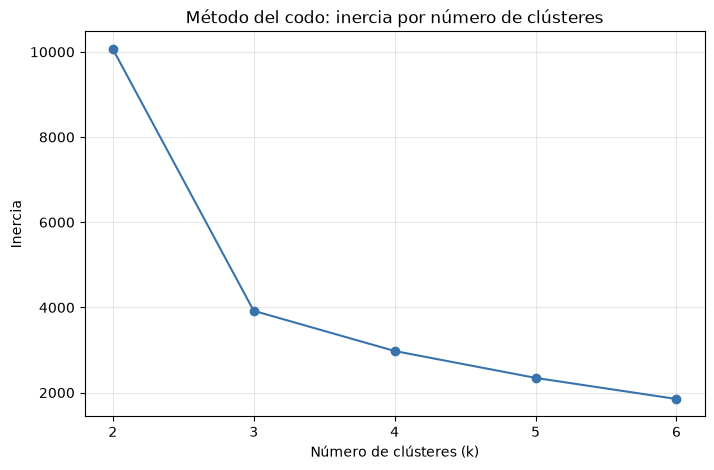

In [12]:
# Gráfica 1: método del codo (inercia)
plt.figure(figsize=(8, 5))
plt.plot(tabla_k["k"], tabla_k["Inercia"], marker="o", color="#3973ac")
plt.title("Método del codo: inercia por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

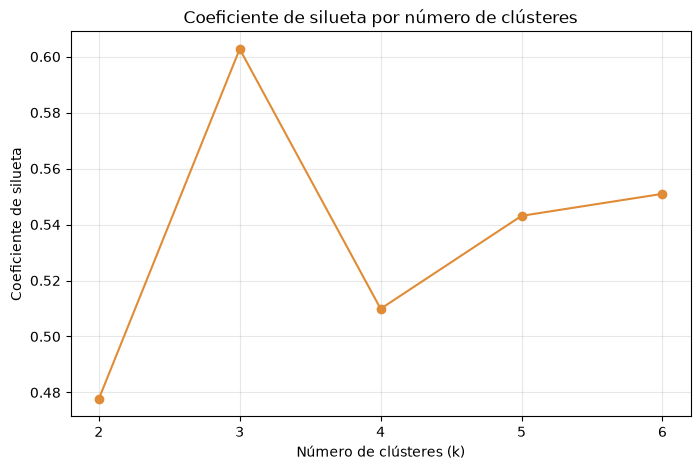

In [13]:
# Gráfica 2: coeficiente de silueta
plt.figure(figsize=(8, 5))
plt.plot(tabla_k["k"], tabla_k["Silueta"], marker="o", color="#e08b36")
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

**Lectura de las métricas.** En la curva de inercia la caída fuerte ocurre al
pasar de `k=2` a `k=3`, y a partir de ahí la mejora es cada vez menor: el "codo"
está en **k = 3**. La silueta confirma esa elección, porque alcanza su valor más
alto justamente en `k = 3`. Agregar más grupos divide los datos sin ganar
separación. Por eso el modelo final usa **k = 3**.

## 6. Modelo final y visualización — 14 puntos

Entrenamos el modelo final con `k = 3` y dibujamos los viajes en el espacio
**transformado y estandarizado** (el mismo que usa K-Means), coloreados por
clúster, con los centroides marcados.

In [14]:
k_final = 3

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas_final = modelo_final.fit_predict(X_escalado)

print("Modelo final entrenado con k =", k_final)
print("Tamaño de cada clúster:")
print(pd.Series(etiquetas_final).value_counts().sort_index())

Modelo final entrenado con k = 3
Tamaño de cada clúster:
0    2406
1    4699
2    2589
Name: count, dtype: int64


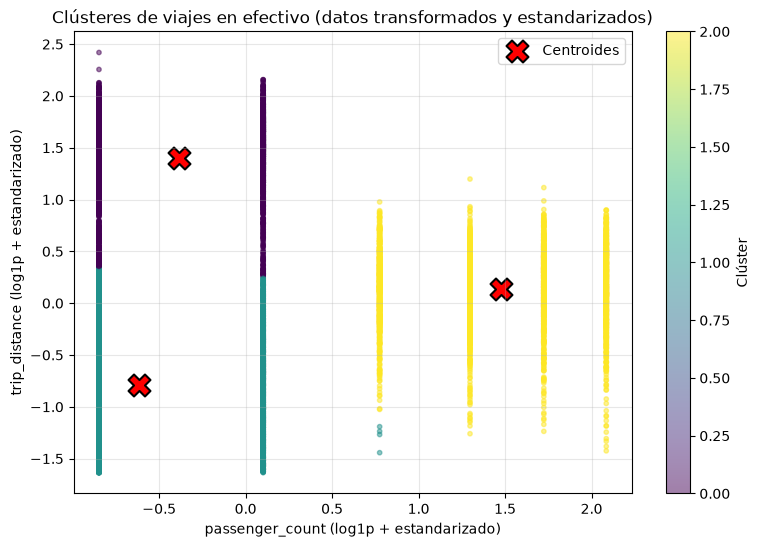

In [15]:
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(9, 6))
dispersion = plt.scatter(
    X_escalado[:, 0], X_escalado[:, 1],
    c=etiquetas_final, cmap="viridis", s=10, alpha=0.5
)
plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=250, c="red", edgecolor="black", linewidth=1.5,
    label="Centroides"
)
plt.title("Clústeres de viajes en efectivo (datos transformados y estandarizados)")
plt.xlabel("passenger_count (log1p + estandarizado)")
plt.ylabel("trip_distance (log1p + estandarizado)")
plt.legend()
plt.colorbar(dispersion, label="Clúster")
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos

### Parte A. Tabla de estadísticos

Los estadísticos se calculan sobre las **unidades originales** (`df_cash`), no
sobre los datos escalados. Solo usamos las etiquetas del modelo para agrupar.

In [16]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas_final

estadisticos = (
    df_resultado
    .groupby("cluster")
    .agg(
        cantidad_viajes=("cluster", "size"),
        passenger_media=("passenger_count", "mean"),
        passenger_mediana=("passenger_count", "median"),
        distancia_media=("trip_distance", "mean"),
        distancia_mediana=("trip_distance", "median"),
    )
    .round(2)
)

estadisticos

,cantidad_viajes,passenger_media,passenger_mediana,distancia_media,distancia_mediana
cluster,,,,,
0,2406,1.49,1.0,12.16,12.53
1,4699,1.25,1.0,1.62,1.38
2,2589,4.51,5.0,4.09,4.05


### Parte B. Preguntas de análisis

**1. ¿Cuántos clústeres se eligieron y cómo se justifica esa decisión?**

Se eligieron **k = 3**. La curva de inercia (método del codo) cae de forma
pronunciada al pasar de `k = 2` a `k = 3` y después se aplana: agregar más
grupos ya casi no reduce la inercia. El coeficiente de silueta apoya la misma
decisión, porque alcanza su valor **más alto en `k = 3`**. Es decir, tres grupos
es el punto donde los clústeres quedan a la vez compactos y bien separados; más
allá de tres solo se parten grupos sin ganar separación.

**2. ¿Qué representa cada uno de los grupos? (unidades originales)**

Los números de clúster (0, 1, 2) son solo etiquetas que asigna el algoritmo, sin
orden. Según la tabla de la Parte A, cada grupo corresponde a un tipo de viaje:

- **Clúster 1 — viajes individuales cortos:** mediana de **1 pasajero** y
  alrededor de **1.4 millas**. Es el grupo más numeroso; son desplazamientos
  rápidos dentro de la ciudad.
- **Clúster 0 — viajes largos de pocos pasajeros:** mediana de **1 pasajero**
  pero cerca de **12.5 millas**. Encaja con trayectos tipo aeropuerto o entre
  zonas alejadas.
- **Clúster 2 — viajes en grupo:** mediana de **5 pasajeros** y distancias
  intermedias (**~4 millas**). Son viajes compartidos por varias personas.

**3. Respuesta a la pregunta guía.** Entre los viajes pagados en efectivo se
identifican **tres tipos** según la cantidad de pasajeros y la distancia:
*individuales cortos*, *largos de pocos pasajeros* y *en grupo*. Lo que más
separa a los grupos es la combinación de esas dos variables: la distancia
distingue los cortos de los de aeropuerto, y el número de pasajeros separa los
viajes en grupo del resto.

**4. ¿Por qué se transformaron las variables antes de agrupar?**

Porque K-Means mide distancias: sin transformar, `trip_distance` (con valores
grandes y cola larga) dominaría sobre `passenger_count`. `np.log1p` comprime las
colas largas y `StandardScaler` deja ambas variables con media 0 y desviación 1,
de modo que pesen por igual en el agrupamiento.

**5. Limitaciones del análisis.** El modelo usa **solo dos variables**, así que
no toma en cuenta otros factores (hora, zona, tarifa, duración). Además K-Means
asume grupos de tamaño y forma parecidos y depende de la escala y del valor de
`k`; por eso la elección de `k` y la transformación previa son parte del
resultado, no detalles menores.